Import and load dataset

In [119]:
!wget "https://raw.githubusercontent.com/durveshcollegeid/sem5_ML/refs/heads/main/oct16/sonar_data_kaggle.csv"

--2026-10-16 04:50:26--  https://raw.githubusercontent.com/durveshcollegeid/sem5_ML/refs/heads/main/oct16/sonar_data_kaggle.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 87776 (86K) [text/plain]
Saving to: ‘sonar_data_kaggle.csv.4’

sonar_data_kaggle.c 100%[===================>]  85.72K  --.-KB/s    in 0.01s   

2026-10-16 04:50:27 (7.07 MB/s) - ‘sonar_data_kaggle.csv.4’ saved [87776/87776]



In [120]:
path = "/content/sonar_data_kaggle.csv"

In [121]:
import pandas as pd

In [122]:
dataset = pd.read_csv(path)

since the dataset doesnt contain a column list, add them manually

In [123]:
dims = len(dataset.columns)
print( dims )

61


In [124]:
col_list = [ ]

for i in range( 1, dims ) :
  col_list.append( "f"+str(i) )

col_list.append( "y" )

In [125]:
#print(col_list)

In [126]:
dataset.columns = col_list

In [127]:
print(dataset.columns)

Index(['f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11',
       'f12', 'f13', 'f14', 'f15', 'f16', 'f17', 'f18', 'f19', 'f20', 'f21',
       'f22', 'f23', 'f24', 'f25', 'f26', 'f27', 'f28', 'f29', 'f30', 'f31',
       'f32', 'f33', 'f34', 'f35', 'f36', 'f37', 'f38', 'f39', 'f40', 'f41',
       'f42', 'f43', 'f44', 'f45', 'f46', 'f47', 'f48', 'f49', 'f50', 'f51',
       'f52', 'f53', 'f54', 'f55', 'f56', 'f57', 'f58', 'f59', 'f60', 'y'],
      dtype='object')


split the dataset into features(X) and target(y)

In [128]:
y = dataset["y"]

In [129]:
X = dataset.drop("y", axis=1)

map "R"(rocks) -> 0 and "M"(mines) -> 1

In [130]:
y = y.map( {"R":0, "M":1} )

funtionize the train-evaluate-plot steps

In [131]:
def usual_pipeline( model, X, y) :
  from sklearn.model_selection import train_test_split

  X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42 )

  model.fit( X_train, y_train )

  y_pred = model.predict( X_test )

  from sklearn.metrics import accuracy_score

  acc = accuracy_score( y_test, y_pred )

  return acc

create a function to create a pie chart plot

In [132]:
def create_pie_plot( metric, title ) :
  import matplotlib.pyplot as plt

  plt.pie( [ metric*100, (1-metric)*100 ], labels = [ "match", "mismatch" ], colors = [ "blue", "red" ], autopct="%0.2f%%" )
  plt.title( title )

  plt.show()

# Task 1 : train a model on the default dataset as baseline

In [133]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [134]:
model = DecisionTreeClassifier()

In [135]:
acc = usual_pipeline( model, X, y )

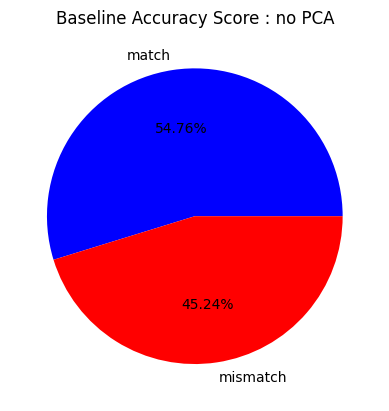

In [136]:
create_pie_plot( acc, "Baseline Accuracy Score : no PCA" )

# Task 2 : evaluate after PCA of 95% variance

In [137]:
from sklearn.decomposition import PCA

In [138]:
pca_95 = PCA( n_components=0.95 )

In [139]:
X_pca_95 = pca_95.fit_transform( X )

In [140]:
acc_pca_95 = usual_pipeline( model, X_pca_95, y )

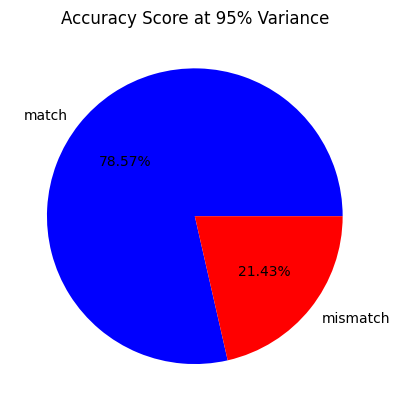

In [141]:
create_pie_plot( acc_pca_95, "Accuracy Score at 95% Variance" )

# Task 3 : PCA with 2, 3, 10 components

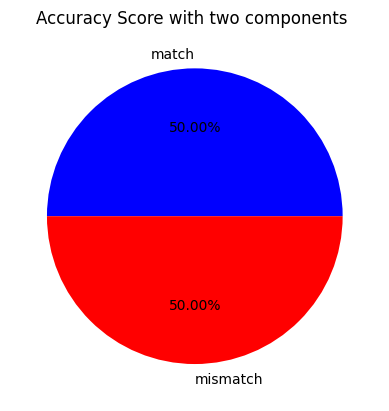

In [142]:
X_pca_two = PCA( n_components=2 ).fit_transform( X )

acc_pca_two = usual_pipeline( model, X_pca_two, y )
create_pie_plot(acc_pca_two, "Accuracy Score with two components ")

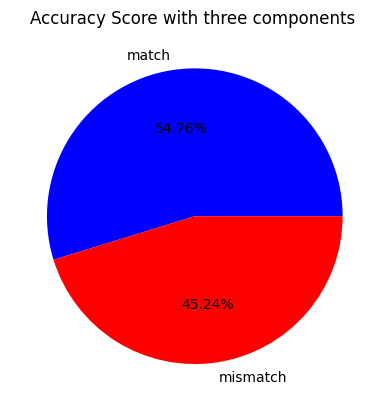

In [143]:
X_pca_three = PCA( n_components=3 ).fit_transform( X )

acc_pca_three = usual_pipeline( model, X_pca_three, y )
create_pie_plot(acc_pca_three, "Accuracy Score with three components ")

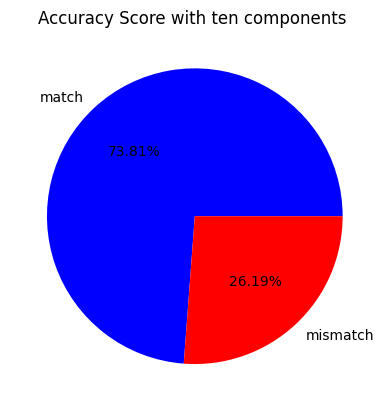

In [144]:
X_pca_ten = PCA( n_components=10 ).fit_transform( X )

acc_pca_ten = usual_pipeline( model, X_pca_ten, y )
create_pie_plot(acc_pca_ten, "Accuracy Score with ten components " )